# BART-large-MNLI: zero-shot text classification (CPU inference)

Classifies text into **labels you make up on the spot**, with no training. Test sets: 40 news articles (AG News, 4 topics) and
20 movie reviews (IMDB, positive/negative), plus custom multi-label examples and a **document-type classifier**
built on SmolDocling's output from the OCR notebook (`../ocr_test`), plus a pointer to GLiNER for field extraction.

| | |
|---|---|
| Model | `facebook/bart-large-mnli` (407M parameters, MIT license) |
| Runs on CPU? | **Yes.** ~1.6 GB of RAM. Each (text, label) pair is one forward pass, ~0.6 s on this CPU, so 4 labels ≈ 2.5 s per text. A GPU is used automatically if present. |
| Language | **English only.** For other languages use a multilingual NLI model such as `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`. |

> **What it does:** BART-large is a 407M-parameter transformer that was fine-tuned on **MNLI** (Multi-Genre Natural Language Inference):
> given a **premise** and a **hypothesis**, it says whether the hypothesis is **entailed** (follows), **neutral**, or **contradicted**.
> **Zero-shot classification** reuses this: every candidate label becomes a hypothesis, e.g. *"This example is about sports."*,
> and the label whose hypothesis is most strongly entailed by the text wins. So you can classify into any labels without training.
>
> | | |
> |---|---|
> | **Input** | a text (premise) + a list of candidate labels + optionally a `hypothesis_template` such as `"This news article is about {}."` |
> | **Output** | `{"sequence": ..., "labels": [...sorted best first], "scores": [...]}`. Single-label: the scores sum to 1. `multi_label=True`: each label is scored on its own, from 0 to 1. |
> | **Raw NLI output** | 3 probabilities: `contradiction`, `neutral`, `entailment` |
> | **Needs from you** | label names, and ideally a good template. **Wording matters a lot** (section 2). |
>
> **Cost:** one forward pass per (text, label) pair, so time grows with the number of labels. Texts are truncated to 1,024 tokens.

In [1]:
import time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, confusion_matrix
from transformers import pipeline
from transformers.utils import logging as hf_logging

warnings.filterwarnings("ignore"); hf_logging.set_verbosity_error()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| torch", torch.__version__)
DATA = Path("data"); OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
pd.set_option("display.max_colwidth", 110)

/home/tsubame/miniconda3/envs/ocr/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cpu | torch 2.15.0+cpu


## Settings and model

In [2]:
MODEL_ID = "facebook/bart-large-mnli"
BATCH_SIZE = 8

t = time.time()
zs = pipeline("zero-shot-classification", model=MODEL_ID, device=DEVICE)
model, tok = zs.model, zs.tokenizer
print(f"{MODEL_ID}: {sum(p.numel() for p in model.parameters()) / 1e6:.0f}M params, loaded in {time.time() - t:.1f}s")
print("NLI classes:", model.config.id2label)

def classify(texts, labels, template="This example is {}.", multi_label=False):
    t = time.time()
    out = zs(list(texts), candidate_labels=labels, hypothesis_template=template, multi_label=multi_label, batch_size=BATCH_SIZE)
    out = [out] if isinstance(out, dict) else out
    return out, time.time() - t

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Loading weights:   7%|▋         | 35/515 [00:00<00:01, 341.87it/s]

Loading weights:  14%|█▎        | 70/515 [00:00<00:02, 206.18it/s]

Loading weights:  20%|█▉        | 102/515 [00:00<00:01, 220.24it/s]

Loading weights:  26%|██▌       | 132/515 [00:00<00:01, 240.66it/s]

Loading weights:  31%|███       | 158/515 [00:00<00:01, 234.40it/s]

... (2 outputs left out)

Loading weights:  49%|████▊     | 250/515 [00:01<00:01, 155.03it/s]

Loading weights:  60%|██████    | 311/515 [00:01<00:00, 243.52it/s]

Loading weights: 100%|██████████| 515/515 [00:01<00:00, 358.45it/s]

facebook/bart-large-mnli: 407M params, loaded in 2.8s
NLI classes: {0: 'contradiction', 1: 'neutral', 2: 'entailment'}


## 1. The underlying task: natural language inference (NLI)

Before zero-shot, here's what the model was actually trained to do: read a premise and a hypothesis, and decide the relation.

In [3]:
PAIRS = [
    ("A man is playing a guitar on stage.", "A person is making music."),
    ("A man is playing a guitar on stage.", "The man is asleep at home."),
    ("A man is playing a guitar on stage.", "The concert is sold out."),
    ("The invoice total is $978.12, due in 30 days.", "This document asks for a payment."),
]
rows = []
for premise, hypothesis in PAIRS:
    enc = tok(premise, hypothesis, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        p = torch.softmax(model(**enc).logits, -1)[0].tolist()
    rows.append({"premise": premise, "hypothesis": hypothesis, **{model.config.id2label[i]: round(v, 3) for i, v in enumerate(p)}})
display(pd.DataFrame(rows))

,premise,hypothesis,contradiction,neutral,entailment
0,A man is playing a guitar on stage.,A person is making music.,0.000,0.004,0.996
1,A man is playing a guitar on stage.,The man is asleep at home.,1.000,0.000,0.000
2,A man is playing a guitar on stage.,The concert is sold out.,0.002,0.998,0.000
3,"The invoice total is $978.12, due in 30 days.",This document asks for a payment.,0.001,0.010,0.989


## 2. News topics (AG News, 40 articles): label wording matters

Same model, same texts, three ways of phrasing the labels:
1. **Plain labels** with the default template `"This example is {}."`
2. **Descriptive labels:** "world politics and international affairs" instead of "world", and so on.
3. **Descriptive labels + a task template:** `"This news article is about {}."`

In [4]:
AG = pd.read_csv(DATA / "ag_news_40.csv")
SETUPS = {
    "plain labels": ({"world": "world", "sports": "sports", "business": "business", "science/technology": "science/technology"},
                     "This example is {}."),
    "descriptive labels": ({"world": "world politics and international affairs", "sports": "sports",
                            "business": "business, companies and the economy", "science/technology": "science, technology and computers"},
                           "This example is {}."),
    "descriptive + template": ({"world": "world politics and international affairs", "sports": "sports",
                                "business": "business, companies and the economy", "science/technology": "science, technology and computers"},
                               "This news article is about {}."),
}
AG_RESULTS = {}
for setup, (label_map, template) in SETUPS.items():
    back = {v: k for k, v in label_map.items()}
    out, secs = classify(AG.text, list(label_map.values()), template)
    pred = [back[o["labels"][0]] for o in out]
    AG_RESULTS[setup] = {"pred": pred, "conf": [o["scores"][0] for o in out], "secs": secs}
    print(f"{setup:24s} accuracy {accuracy_score(AG.label, pred):.0%}   ({secs:.0f}s, {secs / len(AG):.1f}s per article)", flush=True)

plain labels             accuracy 57%   (40s, 1.0s per article)


descriptive labels       accuracy 65%   (45s, 1.1s per article)


descriptive + template   accuracy 62%   (47s, 1.2s per article)


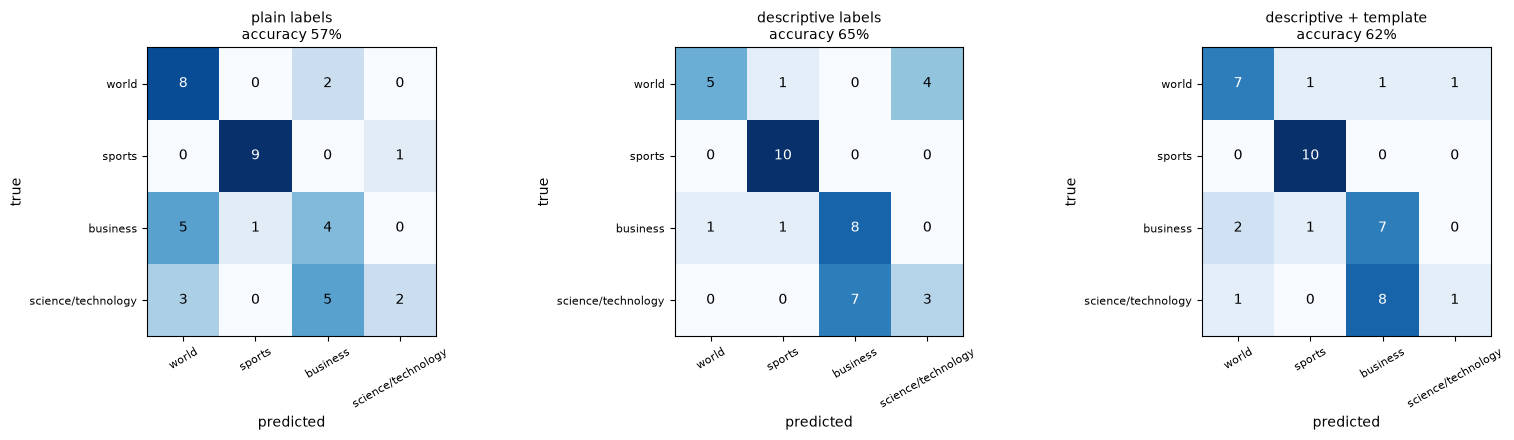

best setup: descriptive labels. Mistakes:


,text,label,predicted,confidence
0,Racing in an Evening Gown (Forbes.com) Forbes.com - Not every driver was dressed formally for the start of...,business,sports,0.799
2,Oil Hits \$46 as YUKOS Cuts China Supply LONDON (Reuters) - Oil prices hit \$46 on Monday after Russia's...,business,world,0.372
3,Australia establish 300-run lead in third India Test (AFP) AFP - Australia batted cautiously in their seco...,world,sports,0.792
11,"Netopia to Restate Results (Reuters) Reuters - Netopia Inc. a maker of\networking gear, on Thursday said ...",science/technology,business,0.844
12,Safety concerns stand in way of space tourism Thrill seekers are plunking down six figures to ride rockets...,science/technology,business,0.660
13,Victory Looms for Karzai as Vote Probe Continues Hamid Karzai was assured of a majority in Afghanistans el...,world,science/technology,0.334
15,Gateway Reports Smaller Quarterly Loss Gateway Inc. reported a narrowed net loss in the first quarter as i...,science/technology,business,0.495
16,"Kyocera Battery Recall Kyocera Battery Recall By guest contributor Josh Pereira. Kyocera, a leading manufa...",science/technology,business,0.665
18,Bourses set for losses after Wall St falls (FT.com) FT.com - European equity markets were poised for openi...,science/technology,business,0.546
24,"P2P Services in the Clear In a major setback for the music and movie industries, a federal appeals court u...",science/technology,business,0.405


In [5]:
best = max(AG_RESULTS, key=lambda s: accuracy_score(AG.label, AG_RESULTS[s]["pred"]))
classes = ["world", "sports", "business", "science/technology"]
fig, axes = plt.subplots(1, len(AG_RESULTS), figsize=(16, 4.5))
for ax, (setup, r) in zip(axes, AG_RESULTS.items()):
    cm = confusion_matrix(AG.label, r["pred"], labels=classes)
    ax.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > 5 else "black")
    ax.set_xticks(range(4), classes, rotation=30, fontsize=8); ax.set_yticks(range(4), classes, fontsize=8)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"{setup}\naccuracy {accuracy_score(AG.label, r['pred']):.0%}", fontsize=10)
plt.tight_layout(); plt.show()

r = AG_RESULTS[best]
AG_OUT = AG.assign(predicted=r["pred"], confidence=np.round(r["conf"], 3))
AG_OUT.to_csv(OUT / "ag_news_predictions.csv", index=False)
print(f"best setup: {best}. Mistakes:")
display(AG_OUT[AG_OUT.label != AG_OUT.predicted])

## 3. Sentiment (IMDB, 20 reviews)

Labels `positive` / `negative` with the template `"The sentiment of this review is {}."`

In [6]:
IM = pd.read_csv(DATA / "imdb_20.csv")
out, IM_SECS = classify(IM.text, ["positive", "negative"], "The sentiment of this review is {}.")
IM_OUT = IM.assign(predicted=[o["labels"][0] for o in out], confidence=[round(o["scores"][0], 3) for o in out])
IM_OUT.to_csv(OUT / "imdb_predictions.csv", index=False)
print(f"accuracy {accuracy_score(IM.label, IM_OUT.predicted):.0%} ({IM_SECS:.0f}s, {IM_SECS / len(IM):.1f}s per review)")
display(IM_OUT.assign(text=IM_OUT.text.str[:150] + "…")[["text", "label", "predicted", "confidence"]].head(8))

accuracy 90% (31s, 1.5s per review)


,text,label,predicted,confidence
0,"Heya Denver fans! The animation is a cartoon's classic & one of my favorite too (and yes, it was broadcast...",positive,positive,0.979
1,"Look, this film is terrible... the ""plot"" involves twins who are neglected by their self-absorbed parents,...",negative,negative,0.994
2,"Although this was a low budget film and clearly last minute, it holds a certain charm that is difficult to...",positive,positive,0.964
3,"I don't know, maybe I just wasn't in the mood for this kind of movie, but it was full of trite melodrama. ...",negative,negative,0.982
4,"I feel as though I know these people and have known people similar to them. These days, though, people are...",positive,positive,0.983
5,This movie makes you think. It shows how a woman's weaknesses can result in nightmares for others. Her phy...,positive,negative,0.801
6,Thank God for DVR and the high speed of it's fast forward. Even with that I couldn't sit through any more ...,negative,negative,0.990
7,"This movie will likely be too sentimental for many viewers, especially contemporary audiences. Nevertheles...",positive,positive,0.974


## 4. Multi-label: several labels can be true at once

With `multi_label=True`, each label gets its own 0–1 score (entailment vs contradiction), so the scores don't compete.
Example: routing customer messages, where a message can be both a complaint *and* about billing.

In [7]:
MESSAGES = [
    "I was charged twice for my subscription this month and nobody answers my emails. This is unacceptable!",
    "The app crashes every time I try to upload a photo on my Android phone.",
    "Could you tell me if you ship to the Philippines and how long delivery takes?",
    "Thanks a lot, the replacement arrived early and works perfectly.",
]
LABELS = ["billing or payment", "technical problem", "shipping or delivery", "complaint", "praise", "question"]
out, secs = classify(MESSAGES, LABELS, "This message is about {}.", multi_label=True)
table = pd.DataFrame([{l: s for l, s in zip(o["labels"], o["scores"])} for o in out], index=[m[:60] + "…" for m in MESSAGES])[LABELS]
print(f"{secs:.1f}s for {len(MESSAGES)} messages x {len(LABELS)} labels. Scores ≥ 0.5 count as 'yes':")
display(table.style.format("{:.2f}").background_gradient(cmap="Greens", vmin=0, vmax=1))

2.8s for 4 messages x 6 labels. Scores ≥ 0.5 count as 'yes':


,billing or payment,technical problem,shipping or delivery,complaint,praise,question
I was charged twice for my subscription this month and nobod…,0.98,0.30,0.51,0.99,0.01,0.78
The app crashes every time I try to upload a photo on my And…,0.01,1.00,0.01,0.97,0.00,0.64
Could you tell me if you ship to the Philippines and how lon…,0.28,0.46,0.99,0.73,0.01,0.99
"Thanks a lot, the replacement arrived early and works perfec…",0.39,0.58,0.91,0.01,1.00,0.19


## 5. Pipeline: SmolDocling → BART = document-type classifier

SmolDocling turns page images into text in the OCR notebook (`../ocr_test`). BART-MNLI then sorts that text into document types,
with no training. This reads the Markdown that SmolDocling saved in `../ocr_test/outputs/smoldocling/` (run that notebook first)
and checks the result against the file names (5 invoices, 5 receipts). "Scientific paper", "letter" and "bank statement" are extra
distractor labels. Next step after this: extract the fields with GLiNER (`../gliner_test`).

In [8]:
docs = {p.stem: p.read_text() for p in sorted(Path("../ocr_test/outputs/smoldocling").glob("*.md"))}
if not docs:
    print("No SmolDocling outputs found. Run ../ocr_test/ocr_inference.ipynb first.")
else:
    TYPES = {"invoice": "an invoice", "receipt": "a shop receipt", "paper": "a scientific research paper",
             "letter": "a personal letter", "bank": "a bank statement"}
    truth = lambda n: next((k for k in TYPES if n.startswith(k)), "?")
    back = {v: k for k, v in TYPES.items()}
    out, DOC_SECS = classify([t[:3000] for t in docs.values()], list(TYPES.values()), "This document is {}.")
    DOC_OUT = pd.DataFrame({"document": list(docs), "true type": [truth(n) for n in docs],
                            "predicted": [back[o["labels"][0]] for o in out], "confidence": [round(o["scores"][0], 3) for o in out],
                            "runner-up": [f"{back[o['labels'][1]]} ({o['scores'][1]:.2f})" for o in out]})
    DOC_OUT.to_csv(OUT / "document_type_predictions.csv", index=False)
    print(f"accuracy {(DOC_OUT['true type'] == DOC_OUT.predicted).mean():.0%} on {len(DOC_OUT)} documents ({DOC_SECS:.0f}s)")
    display(DOC_OUT)

accuracy 50% on 10 documents (136s)


,document,true type,predicted,confidence,runner-up
0,invoice_1,invoice,invoice,0.933,receipt (0.04)
1,invoice_2,invoice,invoice,0.472,bank (0.19)
2,invoice_3,invoice,invoice,0.907,receipt (0.06)
3,invoice_4,invoice,invoice,0.843,receipt (0.07)
4,invoice_5,invoice,invoice,0.498,bank (0.18)
5,receipt_1,receipt,invoice,0.580,bank (0.16)
6,receipt_2,receipt,bank,0.341,letter (0.29)
7,receipt_3,receipt,invoice,0.301,bank (0.29)
8,receipt_4,receipt,invoice,0.310,bank (0.26)
9,receipt_5,receipt,letter,0.376,paper (0.20)



**What this run showed (CPU):**
- **The NLI core works well:** all 4 premise/hypothesis pairs got the right relation with ≥ 0.99 confidence.
- **News topics: only 57–65%.** Descriptive labels helped (57% → 65%). Most mistakes were business ↔ science/technology
  (tech-company earnings) and world ↔ business (oil prices). These categories overlap, and a model trained on AG News gets 90%+.
  Zero-shot trades accuracy for not needing training data.
- **Sentiment: 90%** (18 of 20), a natural fit for NLI.
- **Multi-label routing:** a message can score high on several labels at once (e.g. billing *and* complaint).
- **Document type from SmolDocling text: 50% (5 of 10).** All 5 invoices were right (3 with ≥ 0.84 confidence).
  All 5 receipts were wrong: they are in **Indonesian**, and BART-MNLI is **English-only**, so it guessed "invoice", "bank statement" or "letter"
  with low confidence (0.30–0.58).
  Fixes to try: a multilingual NLI model (e.g. `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`), more descriptive labels
  ("a shop receipt listing items bought and the total paid"), or a few labelled examples with a small trained classifier.
- **Next step in a document pipeline:** once the type is known, pull out its fields with GLiNER (`../gliner_test`),
  which found 19 of 30 invoice values with descriptive labels.
- **Speed:** ~0.3–0.6 s per (text, label) pair on CPU. 4 labels ≈ 1–1.5 s per text.


## 6. Summary

In [9]:
rows = [{"task": f"AG News topics ({s})", "n": len(AG), "accuracy": accuracy_score(AG.label, r["pred"]), "s per text": r["secs"] / len(AG)}
        for s, r in AG_RESULTS.items()]
rows.append({"task": "IMDB sentiment", "n": len(IM), "accuracy": accuracy_score(IM.label, IM_OUT.predicted), "s per text": IM_SECS / len(IM)})
if "DOC_OUT" in globals():
    rows.append({"task": "document type (SmolDocling text)", "n": len(DOC_OUT), "accuracy": (DOC_OUT["true type"] == DOC_OUT.predicted).mean(), "s per text": DOC_SECS / len(DOC_OUT)})
SUMMARY = pd.DataFrame(rows)
SUMMARY.to_csv(OUT / "summary.csv", index=False)
display(SUMMARY.style.format({"accuracy": "{:.0%}", "s per text": "{:.1f}"}, na_rep="—"))

,task,n,accuracy,s per text
0,AG News topics (plain labels),40,57%,1.0
1,AG News topics (descriptive labels),40,65%,1.1
2,AG News topics (descriptive + template),40,62%,1.2
3,IMDB sentiment,20,90%,1.5
4,document type (SmolDocling text),10,50%,13.6
